# ЛР №3. ImageNet. U-Net: сегментация клеточных ядер

Выполнили:
Исупов Никита Александрович, P3431
Ястребов-Амирханов Алекси, P3432


In [ ]:
import importlib.util
import subprocess
import sys

required = {
    'torch': 'torch', 'torchvision': 'torchvision', 'numpy': 'numpy',
    'pandas': 'pandas', 'scipy': 'scipy', 'sklearn': 'scikit-learn',
    'skimage': 'scikit-image', 'matplotlib': 'matplotlib', 'PIL': 'pillow',
    'requests': 'requests', 'tqdm': 'tqdm',
    'datasets': 'datasets>=4,<6', 'huggingface_hub': 'huggingface_hub>=0.30,<2',
}
missing = [package for module, package in required.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('Библиотеки готовы. Python:', sys.version.split()[0])


Библиотеки готовы. Python: 3.13.15


In [ ]:
from pathlib import Path
from contextlib import nullcontext
from collections import defaultdict
from itertools import product
import copy, gc, hashlib, io, json, os, random, shutil, sys, tarfile, time, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import requests
from tqdm.auto import tqdm
from IPython.display import display, Markdown
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from torchvision.transforms import functional as TF
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             ConfusionMatrixDisplay)
from scipy import ndimage as ndi
from skimage import color, filters, morphology, segmentation

SEED = 42
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'
NUM_WORKERS = 2 if 'google.colab' in sys.modules else 0
BASE = Path('/content/lr3') if Path('/content').exists() else Path.cwd() / 'lr3'
DATA = BASE / 'data'
RESULTS = BASE / 'results'
for directory in [DATA, RESULTS]:
    directory.mkdir(parents=True, exist_ok=True)

def seed_all(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

def sync_device():
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()

def autocast_context():
    return torch.autocast(device_type='cuda', dtype=torch.float16) if USE_AMP else nullcontext()

def make_loader(dataset, batch_size, shuffle=False, seed=SEED):
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=USE_AMP,
                      generator=generator, worker_init_fn=seed_worker)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    random.seed(worker_seed)
    np.random.seed(worker_seed)

def save_json(value, path):
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2, default=str), encoding='utf-8')

def download_file(url, destination):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists() and destination.stat().st_size > 0:
        return destination
    temporary = destination.with_suffix(destination.suffix + '.part')
    with requests.get(url, stream=True, timeout=(30, 120)) as response:
        response.raise_for_status()
        total = int(response.headers.get('Content-Length', 0)) or None
        with temporary.open('wb') as file, tqdm(total=total, unit='B', unit_scale=True,
                                                desc=destination.name) as progress:
            for chunk in response.iter_content(1024 * 1024):
                if chunk:
                    file.write(chunk)
                    progress.update(len(chunk))
    temporary.replace(destination)
    return destination

def pixel_hash(image):
    image = image.convert('RGB')
    return hashlib.sha256(str(image.size).encode() + image.tobytes()).hexdigest()

def show_learning(history, title, score='val_score'):
    frame = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    axes[0].plot(frame.epoch, frame.train_loss, label='train')
    axes[0].plot(frame.epoch, frame.val_loss, label='validation')
    axes[0].set(xlabel='Эпоха', ylabel='Loss', title=title)
    axes[0].legend()
    axes[1].plot(frame.epoch, frame[score])
    axes[1].set(xlabel='Эпоха', ylabel='Validation score')
    plt.tight_layout()
    plt.show()

seed_all()
environment = {'torch': torch.__version__, 'numpy': np.__version__,
               'device': str(DEVICE), 'seed': SEED}
save_json(environment, RESULTS / 'environment.json')
print(environment)
print('Данные:', DATA, '\nРезультаты:', RESULTS)
if DEVICE.type == 'cpu':
    print('Выбран CPU: для полного обучения рекомендуется включить GPU в Colab.')


{'torch': '2.11.0+cu130', 'numpy': '2.1.3', 'device': 'cuda', 'seed': 42}
Данные: /content/lr3/data 
Результаты: /content/lr3/results


## 1. Классификация ImageNet на три метакласса

В каждом метаклассе по пять исходных классов ImageNet-1K. Множества не пересекаются,
каждое объединение имеет общий смысл; класса «всё остальное» нет.

| Метакласс | Исходные классы |
|---|---|
| Водный транспорт | canoe, catamaran, gondola, lifeboat, speedboat |
| Грибы | agaric, bolete, stinkhorn, earthstar, hen-of-the-woods |
| Приборы для измерения времени | analog clock, digital clock, wall clock, stopwatch, sundial |

Используем WordNet ID, поскольку числовые индексы ImageNet зависят от соглашения
конкретной библиотеки. Правильность названий проверяется по таблице 1000 классов.
Одинаковое число изображений каждого исходного класса уменьшает дисбаланс.


In [ ]:
META_NAMES = ['Водный транспорт', 'Грибы', 'Приборы для измерения времени']
META_CLASSES = {
    0: {'n02951358': 'canoe', 'n02981792': 'catamaran', 'n03447447': 'gondola',
        'n03662601': 'lifeboat', 'n04273569': 'speedboat'},
    1: {'n12998815': 'agaric', 'n13054560': 'bolete', 'n13040303': 'stinkhorn',
        'n13044778': 'earthstar', 'n13052670': 'hen-of-the-woods'},
    2: {'n02708093': 'analog clock', 'n03196217': 'digital clock',
        'n04548280': 'wall clock', 'n04328186': 'stopwatch', 'n04355338': 'sundial'},
}
WNID_TO_META = {wnid: meta for meta, classes in META_CLASSES.items() for wnid in classes}
WNID_TO_NAME = {wnid: name for classes in META_CLASSES.values() for wnid, name in classes.items()}
assert len(WNID_TO_META) == 15
mapping_path = download_file(
    'https://storage.googleapis.com/download.tensorflow.org/data/imagenet_class_index.json',
    DATA / 'imagenet_class_index.json')
IMAGENET_INDEX = json.loads(mapping_path.read_text())
assert len(IMAGENET_INDEX) == 1000
imagenet_catalog = pd.DataFrame([
    {'index': int(index), 'wnid': value[0], 'name': value[1]}
    for index, value in IMAGENET_INDEX.items()
]).sort_values('index')
imagenet_catalog.to_csv(RESULTS / 'imagenet_all_1000_classes.csv', index=False)
print('Изучаемый каталог ImageNet:', len(imagenet_catalog), 'классов; полный список сохранён в CSV.')
WNID_TO_INDEX = {value[0]: int(key) for key, value in IMAGENET_INDEX.items()}
for wnid, name in WNID_TO_NAME.items():
    assert wnid in WNID_TO_INDEX, f'Отсутствует класс {wnid}'
    actual = IMAGENET_INDEX[str(WNID_TO_INDEX[wnid])][1]
    assert actual.replace('_', ' ') == name, (name, actual)
class_table = pd.DataFrame([
    {'Метакласс': META_NAMES[meta], 'WNID': wnid, 'Класс ImageNet': name,
     'Индекс torchvision (с 0)': WNID_TO_INDEX[wnid]}
    for meta, classes in META_CLASSES.items() for wnid, name in classes.items()
])
display(class_table)
class_table.to_csv(RESULTS / 'imagenet_metaclasses.csv', index=False)


imagenet_class_index.json:   0%|          | 0.00/35.4k [00:00<?, ?B/s]

Изучаемый каталог ImageNet: 1000 классов; полный список сохранён в CSV.


,Метакласс,WNID,Класс ImageNet,Индекс torchvision (с 0)
0,Водный транспорт,n02951358,canoe,472
1,Водный транспорт,n02981792,catamaran,484
2,Водный транспорт,n03447447,gondola,576
3,Водный транспорт,n03662601,lifeboat,625
4,Водный транспорт,n04273569,speedboat,814
5,Грибы,n12998815,agaric,992
6,Грибы,n13054560,bolete,997
7,Грибы,n13040303,stinkhorn,994
8,Грибы,n13044778,earthstar,995
9,Грибы,n13052670,hen-of-the-woods,996


### 1.1. Загрузка ImageNet


In [ ]:
IMAGENET_SOURCE = 'huggingface'
IMAGENET_ROOT = DATA / 'imagenet'
TRAIN_POOL_PER_CLASS = 150
TEST_PER_CLASS = 50
MAX_HF_SCAN = 400_000
CLS_BATCH_SIZE = 32


In [ ]:
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

def get_hf_token():
    from huggingface_hub import get_token
    token = get_token()
    if not token:
        try:
            from google.colab import userdata
            token = userdata.get('HF_TOKEN')
        except Exception:
            pass
    if not token:
        from getpass import getpass
        token = getpass('HF token (скрытый ввод, доступ к ILSVRC/imagenet-1k): ').strip()
    if not token:
        raise RuntimeError('Для этого способа нужен доступ к ImageNet и токен Hugging Face.')
    return token

def collect_hf_split(source_split, limit, token):
    from datasets import load_dataset, Image as HFImage
    cache = DATA / 'imagenet_hf' / source_split
    cache.mkdir(parents=True, exist_ok=True)
    manifest = cache / f'manifest_{limit}.json'
    if manifest.exists():
        rows = json.loads(manifest.read_text())
        if rows and all(Path(row['path']).is_file() for row in rows):
            return rows
    try:
        stream = load_dataset('ILSVRC/imagenet-1k', split=source_split,
                              streaming=True, token=token)
        # Проверяем реальные метки провайдера, а не полагаемся на сортировку WNID.
        label_names = stream.features['label'].names
        label_to_wnid = {}
        for index, label_name in enumerate(label_names):
            first_alias = label_name.split(',')[0].strip().replace('_', ' ')
            for wnid, expected in WNID_TO_NAME.items():
                if label_name == wnid or first_alias == expected:
                    label_to_wnid[index] = wnid
        assert set(label_to_wnid.values()) == set(WNID_TO_META), (
            'Изменена схема меток Hugging Face. Проверьте названия классов:', label_names[:5])
        stream = stream.cast_column('image', HFImage(decode=False))
        counts = defaultdict(int)
        rows = []
        for seen, example in enumerate(tqdm(stream, desc=f'ImageNet {source_split}'), 1):
            wnid = label_to_wnid.get(int(example['label']))
            if wnid is not None and counts[wnid] < limit:
                raw = example['image']
                file_like = io.BytesIO(raw['bytes']) if raw.get('bytes') is not None else raw['path']
                folder = cache / wnid
                folder.mkdir(exist_ok=True)
                path = folder / f'{counts[wnid]:05d}.png'
                with Image.open(file_like) as image:
                    image.convert('RGB').save(path)
                rows.append({'path': str(path), 'wnid': wnid,
                             'meta': WNID_TO_META[wnid], 'source_split': source_split})
                counts[wnid] += 1
            if all(counts[w] >= limit for w in WNID_TO_META):
                break
            if seen >= MAX_HF_SCAN:
                missing = {w: limit - counts[w] for w in WNID_TO_META if counts[w] < limit}
                raise RuntimeError(f'Достигнут MAX_HF_SCAN={MAX_HF_SCAN}. Не хватает: {missing}. '
                                   'Увеличьте лимит или используйте локальные данные.')
        if any(counts[w] < limit for w in WNID_TO_META):
            raise RuntimeError(f'Поток закончился до сбора квоты: {dict(counts)}')
    except Exception as error:
        raise RuntimeError('Не удалось собрать ImageNet. Проверьте доступ к репозиторию, '
                           'токен, сеть и лимит MAX_HF_SCAN. '
                           'Раздел 2 можно выполнить независимо.') from error
    save_json(rows, manifest)
    return rows

def prepare_classification_data():
    if IMAGENET_SOURCE == 'huggingface':
        token = get_hf_token()
        train_rows = collect_hf_split('train', TRAIN_POOL_PER_CLASS, token)
        test_rows = collect_hf_split('validation', TEST_PER_CLASS, token)
    else:
        raise ValueError('IMAGENET_SOURCE должен быть local или huggingface')
    counts = pd.DataFrame([
        {'wnid': w, 'train_pool': sum(r['wnid'] == w for r in train_rows),
         'test': sum(r['wnid'] == w for r in test_rows)} for w in sorted(WNID_TO_META)])
    display(counts)
    if counts.train_pool.min() < 20 or counts.test.min() < 5:
        raise RuntimeError(f'Недостаточно данных. Положите 15 классов train и validation в '
                           f'{IMAGENET_ROOT}, либо выберите huggingface. '
                           'Нужно минимум 20 train и 5 test изображений каждого исходного класса.')
    # Выровнять исходные классы по минимальному доступному количеству.
    n_train, n_test = int(counts.train_pool.min()), int(counts.test.min())
    train_rows = [r for w in sorted(WNID_TO_META) for r in
                  [x for x in train_rows if x['wnid'] == w][:n_train]]
    test_rows = [r for w in sorted(WNID_TO_META) for r in
                 [x for x in test_rows if x['wnid'] == w][:n_test]]
    frame = pd.DataFrame(train_rows + test_rows)
    hashes = []
    for row in tqdm(frame.itertuples(), total=len(frame), desc='Проверка дублей ImageNet'):
        with Image.open(row.path) as image:
            hashes.append(pixel_hash(image))
    frame['sha256'] = hashes
    conflicting = frame.groupby('sha256').meta.nunique()
    assert not (conflicting > 1).any(), 'Найдены дубли с разными метаклассами.'
    # Оставляем test при конфликте train/test, затем удаляем точные дубли.
    frame = frame.sort_values('source_split', ascending=False).drop_duplicates('sha256')
    pool = frame[frame.source_split == 'train'].copy()
    test = frame[frame.source_split == 'validation'].copy()
    train, val = train_test_split(pool, test_size=0.2, stratify=pool.wnid, random_state=SEED)
    split_frames = {'train': train, 'validation': val, 'test': test}
    for split, part in split_frames.items():
        part = part.copy()
        part['split'] = split
        split_frames[split] = part.reset_index(drop=True)
        assert set(part.wnid) == set(WNID_TO_META), f'В {split} потеряны классы'
    for first, second in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
        assert set(split_frames[first].sha256).isdisjoint(split_frames[second].sha256)
    combined = pd.concat(split_frames.values(), ignore_index=True)
    combined.to_csv(RESULTS / 'imagenet_split.csv', index=False)
    display(pd.crosstab(combined['split'], combined['meta']).rename(columns=dict(enumerate(META_NAMES))))
    return split_frames


In [ ]:
cls_frames = prepare_classification_data()


HF token (скрытый ввод, доступ к ILSVRC/imagenet-1k): ··········


README.md:   0%|          | 0.00/87.6k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/294 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/28 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/294 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/28 [00:00<?, ?it/s]

... (5 outputs left out)

ImageNet validation: 0it [00:00, ?it/s]

,wnid,train_pool,test
0,n02708093,150,50
1,n02951358,150,50
2,n02981792,150,50
3,n03196217,150,50
4,n03447447,150,50
5,n03662601,150,50
6,n04273569,150,50
7,n04328186,150,50
8,n04355338,150,50
9,n04548280,150,50


Проверка дублей ImageNet:   0%|          | 0/3000 [00:00<?, ?it/s]

meta,Водный транспорт,Грибы,Приборы для измерения времени
split,,,
test,250,250,250
train,600,600,598
validation,150,150,150


### 1.2. Обработка данных и модель

Размер входа 224×224 и нормализация ImageNet соответствуют предобученной ResNet‑18.
Для train применяем умеренные случайные обрезки и отражения, для validation/test —
только детерминированные resize и center crop. Это предотвращает случайность
оценки. Изменения масок здесь не нужны: это классификация изображений.

ResNet‑18 выбрана как компактная архитектура, подходящая для бесплатного GPU.
Её вектор признаков имеет 512 компонент. Сравниваем три конфигурации:

1. Замороженная ResNet + `Linear(512, 3)` — базовая модель.
2. Замороженная ResNet + MLP `512 → 128 → 3`, ReLU и Dropout(0.3).
3. Та же MLP + дообучение `layer4`, с меньшим learning rate для backbone.

В экспериментах 1/2 меняется только голова, в 2/3 — обучение последнего блока
и соответствующий LR. BatchNorm backbone остаётся в eval-режиме даже при
дообучении: маленькая подвыборка не должна портить накопленные статистики.
CrossEntropyLoss подходит для трёх взаимоисключающих меток. Softmax перед этим
loss не нужен. AdamW и weight decay контролируют переобучение, early stopping
выбирает эпоху по macro-F1 validation. Test в выборе не участвует.


In [ ]:
CLS_WEIGHTS = models.ResNet18_Weights.IMAGENET1K_V1
CLS_MEAN = [0.485, 0.456, 0.406]
CLS_STD = [0.229, 0.224, 0.225]
cls_train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(), transforms.ToTensor(),
    transforms.Normalize(CLS_MEAN, CLS_STD),
])
cls_eval_transform = CLS_WEIGHTS.transforms()

class ClassificationDataset(Dataset):
    def __init__(self, frame, train=False):
        self.frame = frame.reset_index(drop=True)
        self.transform = cls_train_transform if train else cls_eval_transform
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(row.path) as image:
            tensor = self.transform(ImageOps.exif_transpose(image).convert('RGB'))
        return tensor, int(row.meta)

class MetaResNet(nn.Module):
    def __init__(self, head='mlp', finetune=False, pretrained=True):
        super().__init__()
        self.backbone = models.resnet18(weights=CLS_WEIGHTS if pretrained else None)
        features = self.backbone.fc.in_features
        self.backbone.fc = nn.Identity()
        self.head = (nn.Linear(features, 3) if head == 'linear' else
                     nn.Sequential(nn.Linear(features, 128), nn.ReLU(), nn.Dropout(0.3),
                                   nn.Linear(128, 3)))
        for parameter in self.backbone.parameters():
            parameter.requires_grad = False
        if finetune:
            for parameter in self.backbone.layer4.parameters():
                parameter.requires_grad = True
    def train(self, mode=True):
        super().train(mode)
        self.backbone.eval()  # Зафиксировать BatchNorm; градиенты layer4 сохраняются.
        self.head.train(mode)
        return self
    def forward(self, x):
        return self.head(self.backbone(x))

def classification_epoch(model, loader, loss_fn, optimizer=None, scaler=None):
    training = optimizer is not None
    model.train(training)
    loss_sum, targets, predictions = 0., [], []
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            if training:
                optimizer.zero_grad(set_to_none=True)
            with autocast_context():
                logits = model(images)
                loss = loss_fn(logits, labels)
            if training:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), 5.)
                scaler.step(optimizer)
                scaler.update()
            loss_sum += loss.item() * len(images)
            targets.extend(labels.detach().cpu().tolist())
            predictions.extend(logits.argmax(1).detach().cpu().tolist())
    return {'loss': loss_sum / len(loader.dataset),
            'accuracy': accuracy_score(targets, predictions),
            'macro_f1': f1_score(targets, predictions, labels=[0, 1, 2], average='macro', zero_division=0),
            'y_true': targets, 'y_pred': predictions}

def fit_classifier(config, frames):
    seed_all()
    model = MetaResNet(config['head'], config['finetune']).to(DEVICE)
    train_loader = make_loader(ClassificationDataset(frames['train'], True), CLS_BATCH_SIZE, True)
    val_loader = make_loader(ClassificationDataset(frames['validation']), CLS_BATCH_SIZE)
    counts = np.bincount(frames['train'].meta, minlength=3)
    class_weights = torch.tensor(counts.sum() / (3 * counts), dtype=torch.float32, device=DEVICE)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights)
    groups = [{'params': model.head.parameters(), 'lr': 1e-3}]
    if config['finetune']:
        groups.append({'params': model.backbone.layer4.parameters(), 'lr': 1e-4})
    optimizer = torch.optim.AdamW(groups, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', patience=2, factor=0.5)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    checkpoint = RESULTS / f"cls_{config['name']}.pt"
    best, stale, history = -1., 0, []
    sync_device(); started = time.perf_counter()
    for epoch in range(1, config['epochs'] + 1):
        train = classification_epoch(model, train_loader, loss_fn, optimizer, scaler)
        val = classification_epoch(model, val_loader, loss_fn)
        scheduler.step(val['macro_f1'])
        history.append({'epoch': epoch, 'train_loss': train['loss'], 'val_loss': val['loss'],
                        'val_score': val['macro_f1'], 'train_accuracy': train['accuracy'],
                        'val_accuracy': val['accuracy']})
        print(f"{config['name']} | {epoch:02d}: loss={train['loss']:.4f}; "
              f"val F1={val['macro_f1']:.4f}; val acc={val['accuracy']:.4f}")
        if val['macro_f1'] > best + 1e-6:
            best, stale = val['macro_f1'], 0
            torch.save({'state_dict': model.state_dict(), 'config': config,
                        'epoch': epoch, 'meta_names': META_NAMES}, checkpoint)
        else:
            stale += 1
        if stale >= 4:
            break
    sync_device(); seconds = time.perf_counter() - started
    pd.DataFrame(history).to_csv(RESULTS / f"cls_{config['name']}_history.csv", index=False)
    show_learning(history, config['name'])
    del model, optimizer
    gc.collect()
    if USE_AMP:
        torch.cuda.empty_cache()
    return {'name': config['name'], 'val_macro_f1': best, 'train_seconds': seconds,
            'epochs_run': len(history), 'checkpoint': str(checkpoint)}


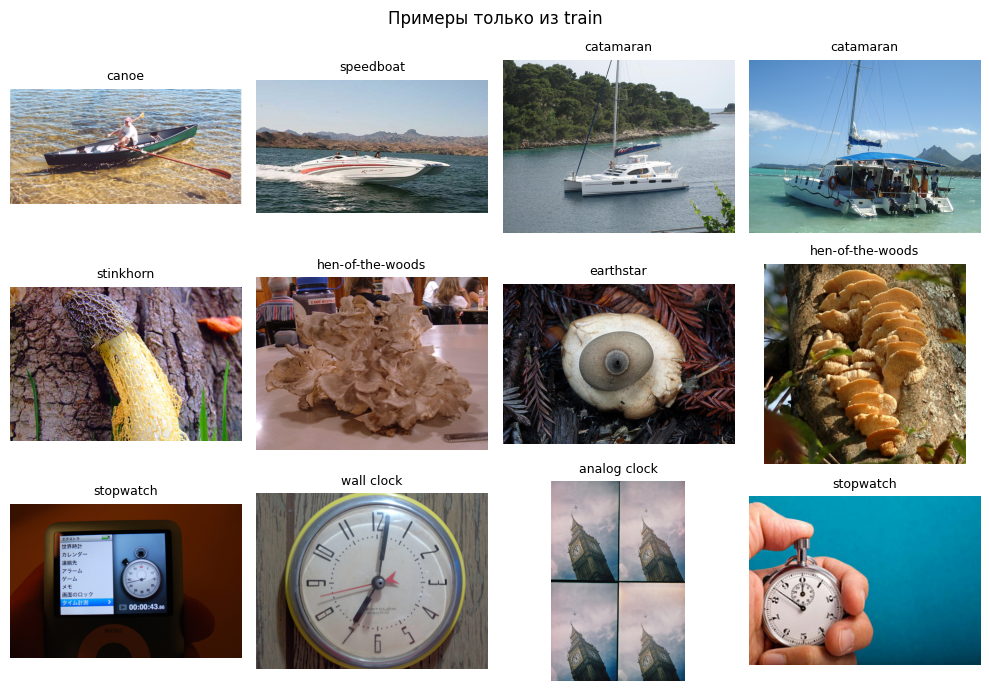

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(10, 7))
for meta in range(3):
    rows = cls_frames['train'].query('meta == @meta').sample(4, random_state=SEED)
    for column, row in enumerate(rows.itertuples()):
        with Image.open(row.path) as image:
            axes[meta, column].imshow(image.convert('RGB'))
        axes[meta, column].set_title(WNID_TO_NAME[row.wnid], fontsize=9)
        axes[meta, column].axis('off')
plt.suptitle('Примеры только из train')
plt.tight_layout(); plt.show()


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 184MB/s]


frozen_linear | 01: loss=0.3100; val F1=0.9889; val acc=0.9889
frozen_linear | 02: loss=0.0484; val F1=0.9911; val acc=0.9911
frozen_linear | 03: loss=0.0331; val F1=0.9911; val acc=0.9911
frozen_linear | 04: loss=0.0267; val F1=0.9911; val acc=0.9911
frozen_linear | 05: loss=0.0214; val F1=0.9889; val acc=0.9889
frozen_linear | 06: loss=0.0180; val F1=0.9889; val acc=0.9889


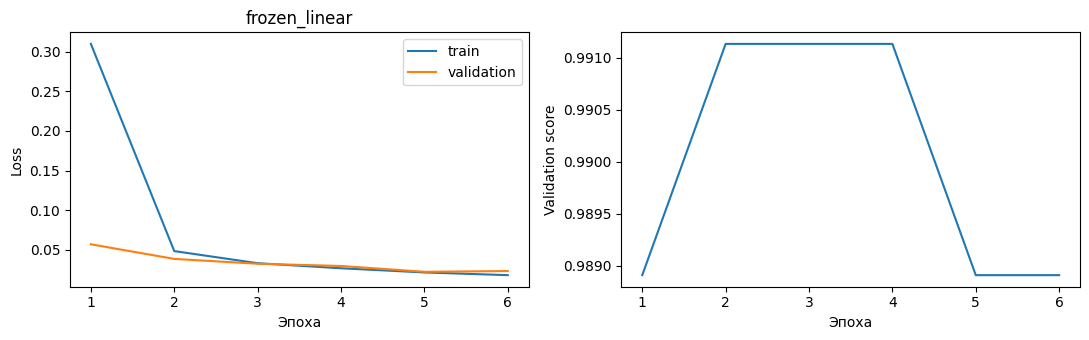

frozen_mlp | 01: loss=0.1541; val F1=0.9933; val acc=0.9933
frozen_mlp | 02: loss=0.0265; val F1=0.9867; val acc=0.9867
frozen_mlp | 03: loss=0.0132; val F1=0.9911; val acc=0.9911
frozen_mlp | 04: loss=0.0113; val F1=0.9844; val acc=0.9844
frozen_mlp | 05: loss=0.0093; val F1=0.9911; val acc=0.9911


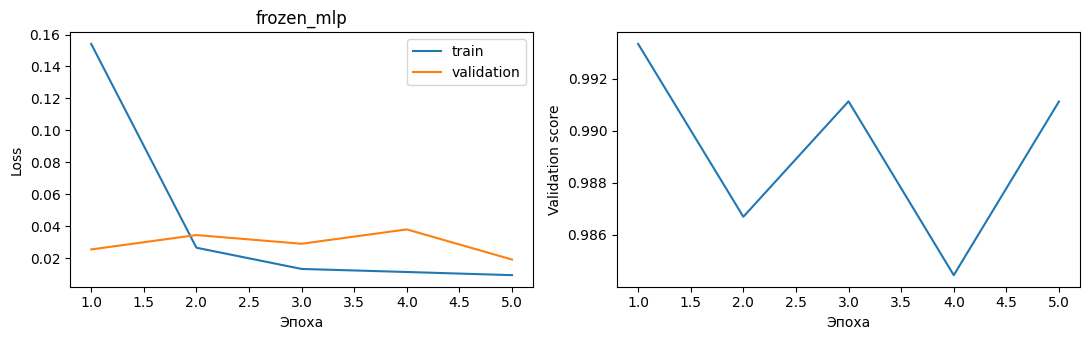

finetune_layer4_mlp | 01: loss=0.2068; val F1=0.9486; val acc=0.9489
finetune_layer4_mlp | 02: loss=0.0243; val F1=0.9911; val acc=0.9911
finetune_layer4_mlp | 03: loss=0.0098; val F1=0.9911; val acc=0.9911
finetune_layer4_mlp | 04: loss=0.0046; val F1=0.9800; val acc=0.9800
finetune_layer4_mlp | 05: loss=0.0290; val F1=0.9800; val acc=0.9800
finetune_layer4_mlp | 06: loss=0.0042; val F1=0.9911; val acc=0.9911


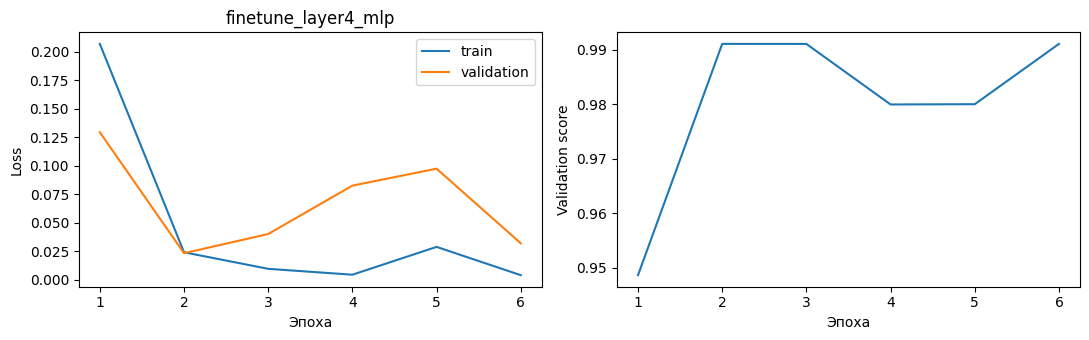

,name,val_macro_f1,train_seconds,epochs_run
0,frozen_linear,0.991132,139.988083,6
1,frozen_mlp,0.993341,115.415128,5
2,finetune_layer4_mlp,0.991111,138.889473,6


In [ ]:
CLS_EXPERIMENTS = [
    {'name': 'frozen_linear', 'head': 'linear', 'finetune': False, 'epochs': 12},
    {'name': 'frozen_mlp', 'head': 'mlp', 'finetune': False, 'epochs': 12},
    {'name': 'finetune_layer4_mlp', 'head': 'mlp', 'finetune': True, 'epochs': 12},
]
cls_results = pd.DataFrame([fit_classifier(config, cls_frames) for config in CLS_EXPERIMENTS])
display(cls_results.drop(columns='checkpoint'))
cls_results.to_csv(RESULTS / 'classification_experiments.csv', index=False)


### 1.3. Единственная итоговая оценка на test

Конфигурация и эпоха уже выбраны по validation macro-F1. Теперь открываем test.
Accuracy показывает долю верных ответов, macro-F1 одинаково учитывает все три
метакласса, а матрица ошибок помогает увидеть, какие именно группы путаются.


                               precision    recall  f1-score   support

             Водный транспорт       0.99      1.00      1.00       250
                        Грибы       0.99      1.00      1.00       250
Приборы для измерения времени       1.00      0.98      0.99       250

                     accuracy                           0.99       750
                    macro avg       0.99      0.99      0.99       750
                 weighted avg       0.99      0.99      0.99       750



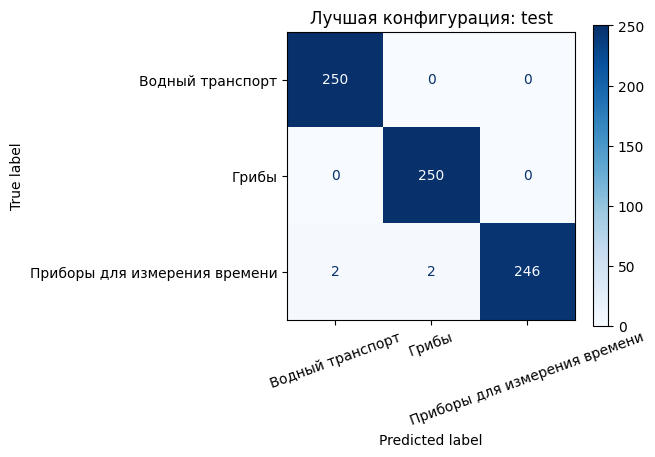

,wnid,accuracy,samples,class_name
8,n04355338,0.96,50,sundial
7,n04328186,0.98,50,stopwatch
9,n04548280,0.98,50,wall clock
0,n02708093,1.00,50,analog clock
3,n03196217,1.00,50,digital clock
4,n03447447,1.00,50,gondola
2,n02981792,1.00,50,catamaran
1,n02951358,1.00,50,canoe
6,n04273569,1.00,50,speedboat
5,n03662601,1.00,50,lifeboat


**Результат задания 1.** По validation выбрана `frozen_mlp` (эпоха 1). Validation macro-F1 = 0.9933, изменение к линейной голове = +0.0022. На test accuracy = **0.9947**, macro-F1 = **0.9947**. Если сложная голова/дообучение не выиграли, это согласуется с тем, что предобученные признаки уже хорошо разделяют эти крупные категории. Выигрыш сложной модели следует оценивать вместе с временем и риском переобучения; один seed не доказывает устойчивость.

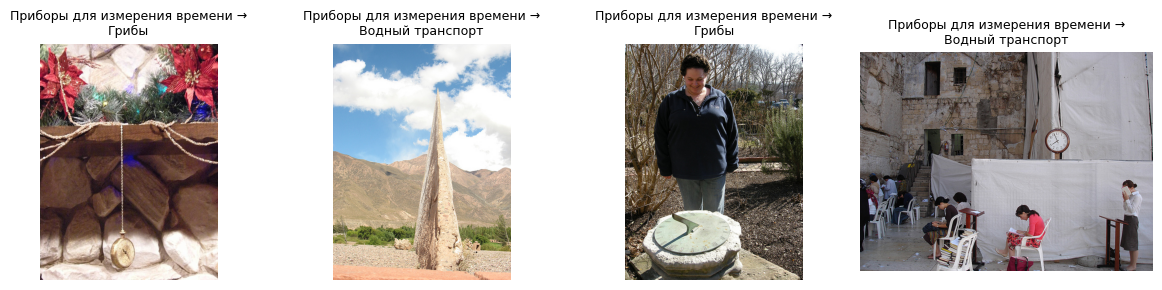

In [ ]:
cls_best_row = cls_results.sort_values(['val_macro_f1', 'train_seconds'], ascending=[False, True]).iloc[0]
cls_checkpoint = torch.load(cls_best_row.checkpoint, map_location='cpu', weights_only=False)
cls_best = MetaResNet(cls_checkpoint['config']['head'], cls_checkpoint['config']['finetune'],
                     pretrained=False).to(DEVICE)
cls_best.load_state_dict(cls_checkpoint['state_dict'])
cls_test_loader = make_loader(ClassificationDataset(cls_frames['test']), CLS_BATCH_SIZE)
cls_test = classification_epoch(cls_best, cls_test_loader, nn.CrossEntropyLoss())
print(classification_report(cls_test['y_true'], cls_test['y_pred'], labels=[0, 1, 2],
                            target_names=META_NAMES, zero_division=0))
ConfusionMatrixDisplay.from_predictions(cls_test['y_true'], cls_test['y_pred'], labels=[0, 1, 2],
                                       display_labels=META_NAMES, xticks_rotation=20, cmap='Blues')
plt.title('Лучшая конфигурация: test'); plt.tight_layout()
plt.savefig(RESULTS / 'classification_confusion.png', dpi=150, bbox_inches='tight')
plt.show()
cls_predictions = cls_frames['test'].copy()
cls_predictions['prediction'] = cls_test['y_pred']
cls_predictions.to_csv(RESULTS / 'classification_test_predictions.csv', index=False)
cls_predictions['correct'] = cls_predictions.meta == cls_predictions.prediction
class_accuracy = cls_predictions.groupby('wnid').agg(
    accuracy=('correct', 'mean'), samples=('correct', 'size')).reset_index()
class_accuracy['class_name'] = class_accuracy.wnid.map(WNID_TO_NAME)
display(class_accuracy.sort_values('accuracy'))
class_accuracy.to_csv(RESULTS / 'classification_per_simple_class.csv', index=False)
save_json({'best_config': cls_checkpoint['config'], 'epoch': cls_checkpoint['epoch'],
           'test_accuracy': cls_test['accuracy'], 'test_macro_f1': cls_test['macro_f1']},
          RESULTS / 'classification_test_metrics.json')
baseline = float(cls_results.loc[cls_results.name == 'frozen_linear', 'val_macro_f1'].iloc[0])
display(Markdown(
    f"**Результат задания 1.** По validation выбрана `{cls_best_row['name']}` "
    f"(эпоха {cls_checkpoint['epoch']}). Validation macro-F1 = {cls_best_row.val_macro_f1:.4f}, "
    f"изменение к линейной голове = {cls_best_row.val_macro_f1 - baseline:+.4f}. "
    f"На test accuracy = **{cls_test['accuracy']:.4f}**, macro-F1 = **{cls_test['macro_f1']:.4f}**. "
    'Если сложная голова/дообучение не выиграли, это согласуется с тем, что предобученные '
    'признаки уже хорошо разделяют эти крупные категории. Выигрыш сложной модели следует '
    'оценивать вместе с временем и риском переобучения; один seed не доказывает устойчивость.'))
errors = cls_predictions[~cls_predictions.correct].head(6)
if len(errors):
    fig, axes = plt.subplots(1, len(errors), figsize=(3 * len(errors), 3), squeeze=False)
    for ax, row in zip(axes[0], errors.itertuples()):
        with Image.open(row.path) as image:
            ax.imshow(image.convert('RGB'))
        ax.set_title(f'{META_NAMES[row.meta]} →\n{META_NAMES[row.prediction]}', fontsize=9)
        ax.axis('off')
    plt.tight_layout(); plt.show()
else:
    print('На этой test-выборке ошибок классификации не найдено.')
del cls_best
gc.collect()
if USE_AMP:
    torch.cuda.empty_cache()


## 2. Семантическая сегментация клеточных ядер

**Датасет:** Data Science Bowl 2018 / BBBC038v1, официальный источник
[Broad Institute](https://bbbc.broadinstitute.org/BBBC038).
Используем `stage1_train.zip` с 670 размеченными изображениями.
Каждая маска исходно соответствует одному ядру. Для задания 2 берём объединение
масок: **0 — фон, 1 — ядро**. Модель не обязана нумеровать отдельные ядра.

Разделение выполняем **до аугментаций** по исходным изображениям. Точные дубли
проверяются по пикселям. Разные источники и способы окрашивания усложняют задачу;
стратификация по типу «почти серое / цветное» лишь частично контролирует этот
разброс. Это не patient-level или experiment-level разбиение: гарантировать
независимость пациентов без соответствующей таблицы связей нельзя.

Ранее в переписке путь после распаковки был указан слишком жёстко: архив может
содержать папки образцов прямо в корне. Здесь структура определяется автоматически.
Также после соревнования опубликованы CSV решений для тестовых стадий; для
лабораторной мы всё равно используем самостоятельное train/validation/test
разбиение исходного размеченного train.


In [ ]:
DSB_URL = 'https://data.broadinstitute.org/bbbc/BBBC038/stage1_train.zip'
DSB_ARCHIVE = DATA / 'stage1_train.zip'
DSB_ROOT = DATA / 'dsb2018'
download_file(DSB_URL, DSB_ARCHIVE)
assert zipfile.is_zipfile(DSB_ARCHIVE), 'Загружен не ZIP: проверьте доступность сервера.'
archive_sha256 = hashlib.sha256(DSB_ARCHIVE.read_bytes()).hexdigest()
save_json({'source': DSB_URL, 'sha256': archive_sha256}, RESULTS / 'dsb_source.json')
marker = DSB_ROOT / '.extracted'
if not marker.exists():
    DSB_ROOT.mkdir(exist_ok=True)
    with zipfile.ZipFile(DSB_ARCHIVE) as archive:
        for member in archive.infolist():
            target = (DSB_ROOT / member.filename).resolve()
            if not target.is_relative_to(DSB_ROOT.resolve()):
                raise ValueError('Некорректный путь в архиве')
        archive.extractall(DSB_ROOT)
    marker.touch()
dsb_samples = sorted(p for p in DSB_ROOT.rglob('*')
                     if p.is_dir() and (p / 'images').is_dir() and (p / 'masks').is_dir())
print('Размеченных образцов:', len(dsb_samples))
assert len(dsb_samples) == 670, 'Для исходного stage1_train ожидается 670 образцов.'


stage1_train.zip:   0%|          | 0.00/82.9M [00:00<?, ?B/s]

Размеченных образцов: 670


In [ ]:
SEG_SIZE = 256  # кратно 16; одинаковый размер для нейросети и классического метода
SEG_BATCH_SIZE = 8

def read_nuclei(sample_dir):
    sample_dir = Path(sample_dir)
    images = sorted((sample_dir / 'images').glob('*.png'))
    masks = sorted((sample_dir / 'masks').glob('*.png'))
    assert len(images) == 1 and masks, sample_dir
    with Image.open(images[0]) as source:
        image = np.array(source.convert('RGB'))
    mask = np.zeros(image.shape[:2], dtype=bool)
    for path in masks:
        with Image.open(path) as source:
            instance = np.array(source.convert('L')) > 0
        assert instance.shape == mask.shape, (sample_dir, instance.shape, mask.shape)
        mask |= instance
    return image, mask

def resize_pair(image, mask, size=SEG_SIZE):
    image = np.array(Image.fromarray(image).resize((size, size), Image.Resampling.BILINEAR))
    mask = np.array(Image.fromarray(mask.astype('uint8') * 255).resize(
        (size, size), Image.Resampling.NEAREST)) > 0
    return image, mask

def normalize_nuclei(image):
    # Процентили вычисляются по текущему изображению, без доступа к его маске.
    image = np.asarray(image, dtype=np.float32) / 255.
    low, high = np.percentile(image, [1, 99])
    return np.clip((image - low) / max(float(high - low), 1e-6), 0, 1).astype(np.float32)

def image_modality(image):
    channels = image.astype(np.float32) / 255.
    chroma = np.mean(np.max(channels, axis=2) - np.min(channels, axis=2))
    return 'color' if chroma > 0.02 else 'gray'

def build_nuclei_manifest(samples):
    rows = []
    for directory in tqdm(samples, desc='Проверка изображений и масок'):
        image, mask = read_nuclei(directory)
        rows.append({'id': directory.name, 'path': str(directory),
                     'modality': image_modality(image), 'height': image.shape[0],
                     'width': image.shape[1], 'foreground_fraction': mask.mean(),
                     'image_hash': pixel_hash(Image.fromarray(image)),
                     'mask_hash': hashlib.sha256(mask.tobytes()).hexdigest()})
    frame = pd.DataFrame(rows)
    if frame.groupby('image_hash').mask_hash.nunique().max() > 1:
        raise RuntimeError('Одинаковые изображения имеют разную разметку: требуется проверка.')
    before = len(frame)
    frame = frame.drop_duplicates('image_hash').reset_index(drop=True)
    print('Удалено точных дублей:', before - len(frame))
    train, remaining = train_test_split(frame, test_size=0.30, stratify=frame.modality,
                                       random_state=SEED)
    val, test = train_test_split(remaining, test_size=0.5, stratify=remaining.modality,
                                random_state=SEED)
    parts = []
    for split, part in [('train', train), ('validation', val), ('test', test)]:
        part = part.copy()
        part['split'] = split
        parts.append(part)
    manifest = pd.concat(parts, ignore_index=True)
    manifest.to_csv(RESULTS / 'nuclei_split.csv', index=False)
    return manifest

class NucleiDataset(Dataset):
    def __init__(self, frame, augment=False, size=SEG_SIZE):
        self.rows = frame.reset_index(drop=True)
        self.augment = augment
        self.size = size
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, index):
        row = self.rows.iloc[index]
        image, mask = resize_pair(*read_nuclei(row.path), size=self.size)
        image = normalize_nuclei(image)
        if self.augment:
            turns = random.randrange(4)
            image, mask = np.rot90(image, turns), np.rot90(mask, turns)
            if random.random() < 0.5:
                image, mask = np.flip(image, axis=1), np.flip(mask, axis=1)
            if random.random() < 0.5:
                image, mask = np.flip(image, axis=0), np.flip(mask, axis=0)
            # Фотометрическое изменение — только для изображения.
            image = np.clip(image ** random.uniform(0.8, 1.2) * random.uniform(0.9, 1.1), 0, 1)
        image = torch.from_numpy(np.ascontiguousarray(image.transpose(2, 0, 1))).float()
        mask = torch.from_numpy(np.ascontiguousarray(mask[None])).float()
        return image, mask, row['id']


Проверка изображений и масок:   0%|          | 0/670 [00:00<?, ?it/s]

Удалено точных дублей: 0


modality,color,gray
split,,
test,16,85
train,76,393
validation,16,84


,height,width,foreground_fraction
split,,,
test,316.752475,354.772277,0.133883
train,339.646055,385.093817,0.140488
validation,324.880000,371.540000,0.138472


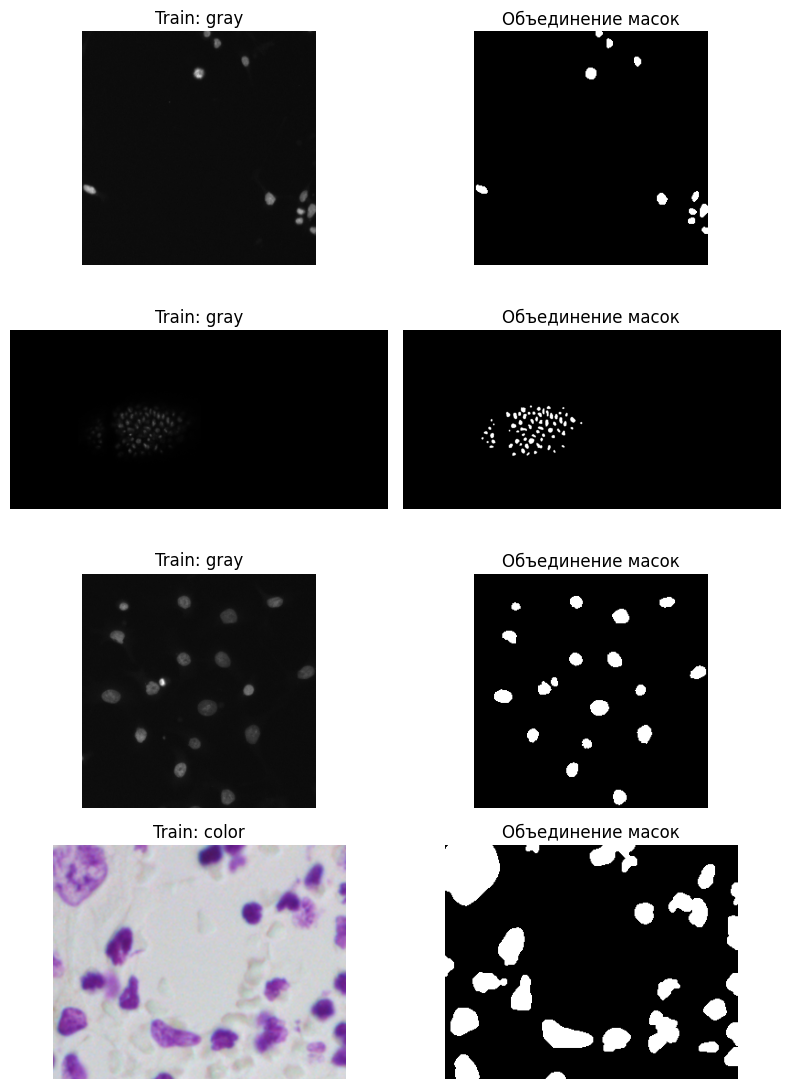

In [ ]:
dsb_manifest = build_nuclei_manifest(dsb_samples)
seg_frames = {split: dsb_manifest.query('split == @split').reset_index(drop=True)
              for split in ['train', 'validation', 'test']}
for a, b in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
    assert set(seg_frames[a].image_hash).isdisjoint(seg_frames[b].image_hash)
display(pd.crosstab(dsb_manifest['split'], dsb_manifest['modality']))
display(dsb_manifest.groupby('split')[['height', 'width', 'foreground_fraction']].mean())

fig, axes = plt.subplots(4, 2, figsize=(8, 11))
for index, row in enumerate(seg_frames['train'].sample(4, random_state=SEED).itertuples()):
    image, mask = read_nuclei(row.path)
    axes[index, 0].imshow(image); axes[index, 0].set_title(f'Train: {row.modality}')
    axes[index, 1].imshow(mask, cmap='gray'); axes[index, 1].set_title('Объединение масок')
    for ax in axes[index]:
        ax.axis('off')
plt.tight_layout(); plt.show()


### 2.1. U-Net и функция потерь

U-Net имеет encoder с четырьмя понижениями размера, bottleneck и симметричный
decoder. Skip connections передают детали границ. Начальная ширина 16 каналов
сокращает память; при достаточном GPU её можно увеличить до 32 отдельным опытом.
GroupNorm выбрана вместо BatchNorm для стабильности при небольшом batch size.
Выход — один канал логитов, вероятность ядра получается через sigmoid.

Все методы оцениваем при 256×256: это упрощает batch и делает сравнение единым,
но уменьшает детализацию мелких ядер и может искажать вытянутые изображения.
Маски изменяют размер только nearest-neighbor. На полном разрешении потребуется
дополнительный эксперимент с тайлами и разделением до нарезки.

**BCEWithLogitsLoss** стабильнее отдельной пары sigmoid + BCE.
**Soft Dice loss** учитывает пересечение областей при дисбалансе фон/ядро.
В смешанном loss их веса равны: `0.5 × BCE + 0.5 × DiceLoss`.
AdamW: LR=0.001, weight_decay=0.0001. LR уменьшается при остановке улучшения.

Эксперименты контролируют по одному изменению:
1. BCE, без аугментаций;
2. BCE + Dice, без аугментаций;
3. BCE + Dice, с синхронными поворотами/отражениями изображения и маски.

Одинаковые seed, ширина модели и лимит эпох. Лучшая эпоха выбирается по validation
Dice при пороге 0.5; затем по validation выбираем порог вероятности и конфигурацию.
Это небольшая учебная серия, а не исчерпывающий поиск лучшего качества.


In [ ]:
class DoubleConv(nn.Sequential):
    def __init__(self, in_channels, out_channels):
        super().__init__(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.GroupNorm(4, out_channels), nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.GroupNorm(4, out_channels), nn.ReLU(inplace=True))

class UNet(nn.Module):
    def __init__(self, base=16):
        super().__init__()
        self.encoders = nn.ModuleList([DoubleConv(3, base), DoubleConv(base, base*2),
                                      DoubleConv(base*2, base*4), DoubleConv(base*4, base*8)])
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(base*8, base*16)
        self.ups = nn.ModuleList([nn.ConvTranspose2d(base*16, base*8, 2, 2),
                                 nn.ConvTranspose2d(base*8, base*4, 2, 2),
                                 nn.ConvTranspose2d(base*4, base*2, 2, 2),
                                 nn.ConvTranspose2d(base*2, base, 2, 2)])
        self.decoders = nn.ModuleList([DoubleConv(base*16, base*8), DoubleConv(base*8, base*4),
                                      DoubleConv(base*4, base*2), DoubleConv(base*2, base)])
        self.final = nn.Conv2d(base, 1, 1)
    def forward(self, x):
        skips = []
        for encoder in self.encoders:
            x = encoder(x)
            skips.append(x)
            x = self.pool(x)
        x = self.bottleneck(x)
        for up, decoder, skip in zip(self.ups, self.decoders, reversed(skips)):
            x = up(x)
            if x.shape[-2:] != skip.shape[-2:]:
                x = nn.functional.interpolate(x, size=skip.shape[-2:], mode='bilinear', align_corners=False)
            x = decoder(torch.cat([skip, x], dim=1))
        return self.final(x)

class SegmentationLoss(nn.Module):
    def __init__(self, mixed=True):
        super().__init__()
        self.mixed = mixed
        self.bce = nn.BCEWithLogitsLoss()
    def forward(self, logits, targets):
        bce = self.bce(logits, targets)
        if not self.mixed:
            return bce
        probabilities = logits.float().sigmoid().flatten(1)
        targets = targets.float().flatten(1)
        intersection = (probabilities * targets).sum(1)
        dice_loss = 1 - ((2 * intersection + 1e-6) /
                         (probabilities.sum(1) + targets.sum(1) + 1e-6)).mean()
        return 0.5 * bce + 0.5 * dice_loss

def binary_metrics(target, prediction):
    target, prediction = np.asarray(target, dtype=bool), np.asarray(prediction, dtype=bool)
    tp = int(np.logical_and(target, prediction).sum())
    fp = int(np.logical_and(~target, prediction).sum())
    fn = int(np.logical_and(target, ~prediction).sum())
    union = tp + fp + fn
    return {'dice': 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 1.,
            'iou': tp / union if union else 1.,
            'precision': tp / (tp + fp) if (tp + fp) else float(not target.any()),
            'recall': tp / (tp + fn) if (tp + fn) else 1.,
            'tp': tp, 'fp': fp, 'fn': fn}

def segmentation_epoch(model, loader, loss_fn, optimizer=None, scaler=None):
    training = optimizer is not None
    model.train(training)
    total_loss, total_dice = 0., 0.
    with torch.set_grad_enabled(training):
        for images, masks, _ in loader:
            images, masks = images.to(DEVICE), masks.to(DEVICE)
            if training:
                optimizer.zero_grad(set_to_none=True)
            with autocast_context():
                logits = model(images)
                loss = loss_fn(logits, masks)
            if training:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), 5.)
                scaler.step(optimizer)
                scaler.update()
            prediction = logits.detach().float().sigmoid().cpu().numpy()[:, 0] >= 0.5
            target = masks.detach().cpu().numpy()[:, 0] > 0.5
            total_dice += sum(binary_metrics(y, p)['dice'] for y, p in zip(target, prediction))
            total_loss += loss.item() * len(images)
    return {'loss': total_loss / len(loader.dataset), 'dice': total_dice / len(loader.dataset)}

@torch.inference_mode()
def predict_segmentation(model, frame):
    loader = make_loader(NucleiDataset(frame), SEG_BATCH_SIZE)
    model.eval()
    output = []
    sync_device(); started = time.perf_counter()
    for images, masks, ids in loader:
        with autocast_context():
            probabilities = model(images.to(DEVICE)).float().sigmoid().cpu().numpy()[:, 0]
        for key, probability, target in zip(ids, probabilities, masks.numpy()[:, 0]):
            output.append({'id': key, 'probability': probability, 'target': target > 0.5})
    sync_device()
    return output, time.perf_counter() - started

def evaluate_probabilities(predictions, threshold):
    return pd.DataFrame([{'id': x['id'], **binary_metrics(x['target'], x['probability'] >= threshold)}
                         for x in predictions])

def fit_unet(config, frames):
    seed_all()
    model = UNet(config['base']).to(DEVICE)
    train_loader = make_loader(NucleiDataset(frames['train'], config['augment']), SEG_BATCH_SIZE, True)
    val_loader = make_loader(NucleiDataset(frames['validation']), SEG_BATCH_SIZE)
    loss_fn = SegmentationLoss(config['mixed_loss'])
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    best, stale, history = -1., 0, []
    checkpoint = RESULTS / f"seg_{config['name']}.pt"
    sync_device(); started = time.perf_counter()
    for epoch in range(1, config['epochs'] + 1):
        train = segmentation_epoch(model, train_loader, loss_fn, optimizer, scaler)
        val = segmentation_epoch(model, val_loader, loss_fn)
        scheduler.step(val['dice'])
        history.append({'epoch': epoch, 'train_loss': train['loss'], 'val_loss': val['loss'],
                        'val_score': val['dice'], 'train_dice': train['dice']})
        print(f"{config['name']} | {epoch:02d}: train loss={train['loss']:.4f}; "
              f"val Dice={val['dice']:.4f}")
        if val['dice'] > best + 1e-6:
            best, stale = val['dice'], 0
            torch.save({'state_dict': model.state_dict(), 'config': config, 'epoch': epoch,
                        'image_size': SEG_SIZE}, checkpoint)
        else:
            stale += 1
        if stale >= 5:
            break
    sync_device(); seconds = time.perf_counter() - started
    saved = torch.load(checkpoint, map_location=DEVICE, weights_only=False)
    model.load_state_dict(saved['state_dict'])
    val_predictions, _ = predict_segmentation(model, frames['validation'])
    threshold_rows = []
    for threshold in np.arange(0.30, 0.71, 0.05):
        metrics = evaluate_probabilities(val_predictions, float(threshold))
        threshold_rows.append({'threshold': float(threshold), 'dice': metrics.dice.mean(),
                               'iou': metrics.iou.mean()})
    threshold_table = pd.DataFrame(threshold_rows)
    selected = threshold_table.sort_values('dice', ascending=False).iloc[0]
    pd.DataFrame(history).to_csv(RESULTS / f"seg_{config['name']}_history.csv", index=False)
    threshold_table.to_csv(RESULTS / f"seg_{config['name']}_thresholds.csv", index=False)
    show_learning(history, config['name'])
    del model, optimizer, val_predictions, saved
    gc.collect()
    if USE_AMP:
        torch.cuda.empty_cache()
    return {'name': config['name'], 'val_dice': selected.dice, 'val_iou': selected.iou,
            'threshold': selected.threshold, 'train_seconds': seconds,
            'epochs_run': len(history), 'checkpoint': str(checkpoint)}


bce_no_aug | 01: train loss=0.3262; val Dice=0.8132
bce_no_aug | 02: train loss=0.1866; val Dice=0.8738
bce_no_aug | 03: train loss=0.1454; val Dice=0.8720
bce_no_aug | 04: train loss=0.1154; val Dice=0.8755
bce_no_aug | 05: train loss=0.1039; val Dice=0.8811
bce_no_aug | 06: train loss=0.0920; val Dice=0.8777
bce_no_aug | 07: train loss=0.0928; val Dice=0.8620
bce_no_aug | 08: train loss=0.0910; val Dice=0.8815
bce_no_aug | 09: train loss=0.0826; val Dice=0.8852
bce_no_aug | 10: train loss=0.0797; val Dice=0.8810
bce_no_aug | 11: train loss=0.0765; val Dice=0.8841
bce_no_aug | 12: train loss=0.0745; val Dice=0.8856
bce_no_aug | 13: train loss=0.0740; val Dice=0.8857
bce_no_aug | 14: train loss=0.0721; val Dice=0.8892
bce_no_aug | 15: train loss=0.0768; val Dice=0.8867
bce_no_aug | 16: train loss=0.0709; val Dice=0.8913
bce_no_aug | 17: train loss=0.0715; val Dice=0.8846
bce_no_aug | 18: train loss=0.0680; val Dice=0.8760


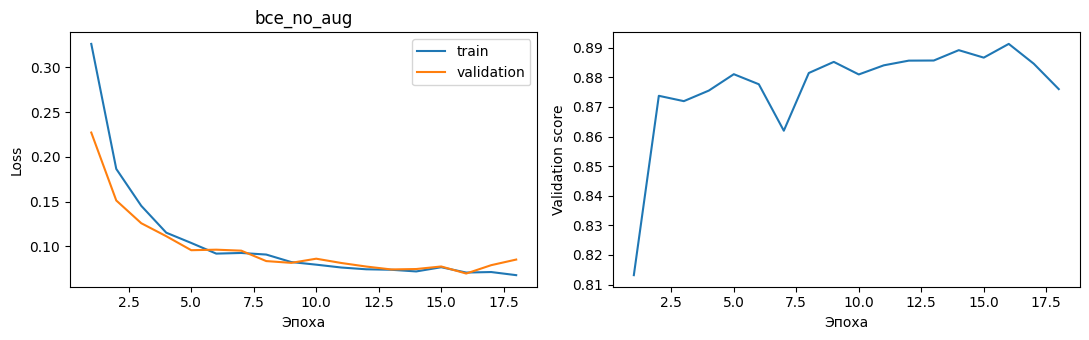

bce_dice_no_aug | 01: train loss=0.4887; val Dice=0.7575
bce_dice_no_aug | 02: train loss=0.3386; val Dice=0.8570
bce_dice_no_aug | 03: train loss=0.2610; val Dice=0.8677
bce_dice_no_aug | 04: train loss=0.2022; val Dice=0.8674
bce_dice_no_aug | 05: train loss=0.1735; val Dice=0.8736
bce_dice_no_aug | 06: train loss=0.1470; val Dice=0.8807
bce_dice_no_aug | 07: train loss=0.1331; val Dice=0.8872
bce_dice_no_aug | 08: train loss=0.1221; val Dice=0.8821
bce_dice_no_aug | 09: train loss=0.1181; val Dice=0.8869
bce_dice_no_aug | 10: train loss=0.1167; val Dice=0.8863
bce_dice_no_aug | 11: train loss=0.1077; val Dice=0.8911
bce_dice_no_aug | 12: train loss=0.1033; val Dice=0.8923
bce_dice_no_aug | 13: train loss=0.1035; val Dice=0.8877
bce_dice_no_aug | 14: train loss=0.1021; val Dice=0.8949
bce_dice_no_aug | 15: train loss=0.1007; val Dice=0.8950
bce_dice_no_aug | 16: train loss=0.0967; val Dice=0.8962
bce_dice_no_aug | 17: train loss=0.0966; val Dice=0.8923
bce_dice_no_aug | 18: train los

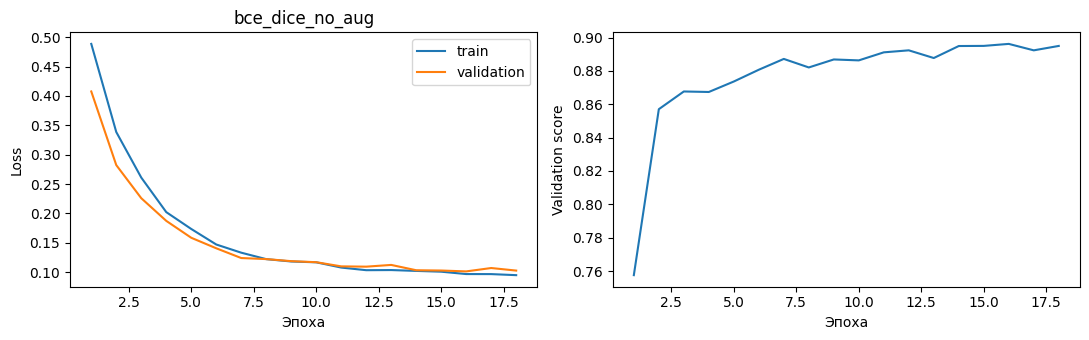

bce_dice_aug | 01: train loss=0.4909; val Dice=0.7424
bce_dice_aug | 02: train loss=0.3427; val Dice=0.8655
bce_dice_aug | 03: train loss=0.2600; val Dice=0.8610
bce_dice_aug | 04: train loss=0.2084; val Dice=0.8747
bce_dice_aug | 05: train loss=0.1796; val Dice=0.8726
bce_dice_aug | 06: train loss=0.1558; val Dice=0.8820
bce_dice_aug | 07: train loss=0.1386; val Dice=0.8769
bce_dice_aug | 08: train loss=0.1281; val Dice=0.8852
bce_dice_aug | 09: train loss=0.1275; val Dice=0.8786
bce_dice_aug | 10: train loss=0.1283; val Dice=0.8819
bce_dice_aug | 11: train loss=0.1143; val Dice=0.8886
bce_dice_aug | 12: train loss=0.1061; val Dice=0.8922
bce_dice_aug | 13: train loss=0.1056; val Dice=0.8905
bce_dice_aug | 14: train loss=0.1081; val Dice=0.8889
bce_dice_aug | 15: train loss=0.1053; val Dice=0.8926
bce_dice_aug | 16: train loss=0.1018; val Dice=0.8903
bce_dice_aug | 17: train loss=0.1008; val Dice=0.8893
bce_dice_aug | 18: train loss=0.0976; val Dice=0.8875


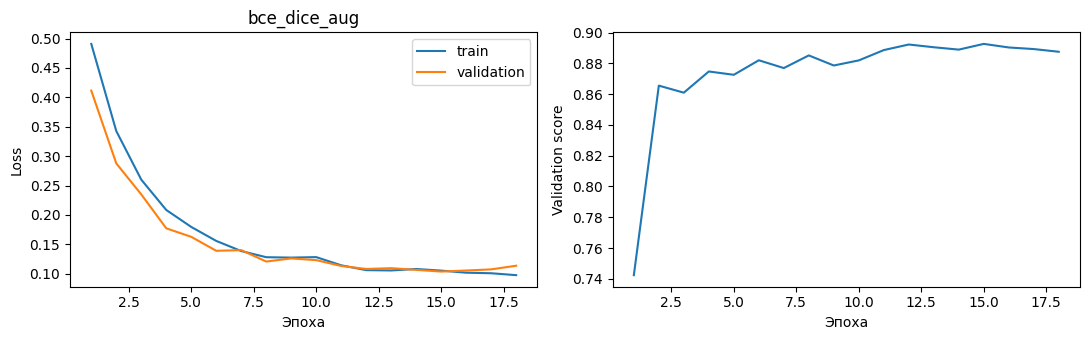

,name,val_dice,val_iou,threshold,train_seconds,epochs_run
0,bce_no_aug,0.892547,0.819075,0.45,404.262968,18
1,bce_dice_no_aug,0.896445,0.826525,0.40,406.857295,18
2,bce_dice_aug,0.892637,0.820362,0.50,416.891256,18


In [ ]:
SEG_EXPERIMENTS = [
    {'name': 'bce_no_aug', 'mixed_loss': False, 'augment': False, 'base': 16, 'epochs': 18},
    {'name': 'bce_dice_no_aug', 'mixed_loss': True, 'augment': False, 'base': 16, 'epochs': 18},
    {'name': 'bce_dice_aug', 'mixed_loss': True, 'augment': True, 'base': 16, 'epochs': 18},
]
seg_results = pd.DataFrame([fit_unet(config, seg_frames) for config in SEG_EXPERIMENTS])
display(seg_results.drop(columns='checkpoint'))
seg_results.to_csv(RESULTS / 'segmentation_experiments.csv', index=False)


### 2.2. Классический алгоритм: Otsu, морфология и Watershed

Алгоритм не использует нейросети и не получает эталонную маску на вход.

1. Нормализовать интенсивность изображения. Для цветной гистологии можно
   использовать канал гематоксилина H из HED; для остальных снимков — grayscale.
2. Автоматически выбрать полярность grayscale по яркости границы относительно
   центра. Это эвристика, которая может ошибаться при сложном фоне.
3. Сгладить шум Gaussian-фильтром, применить Otsu, удалить маленькие компоненты
   и заполнить небольшие отверстия.
4. Вычислить distance transform, найти внутренние маркеры и применить Watershed.

**Важное уточнение:** Watershed разделяет экземпляры, а наша задача — ядро/фон.
Если просто объединить области Watershed без удаления границ, бинарная маска
почти не изменится. Поэтому отдельно сравниваем Otsu с морфологией и вариант
с линиями водораздела. Watershed может как улучшить, так и ухудшить Dice.
Нельзя обещать ему выигрыш только потому, что он разделяет касающиеся ядра.

Параметры классического метода также выбираются только на validation;
test используется единожды после фиксации обоих методов. Сравниваем средние
Dice/IoU по изображениям (macro), а не accuracy, которую завышает большой фон.


In [ ]:
def nuclei_signal(image, mode='gray'):
    rgb = normalize_nuclei(image)
    if mode == 'hed_auto' and image_modality(image) == 'color':
        signal = color.rgb2hed(np.clip(rgb, 1e-6, 1))[..., 0]
        lo, hi = np.percentile(signal, [1, 99])
        return np.clip((signal - lo) / max(float(hi - lo), 1e-6), 0, 1)
    signal = color.rgb2gray(rgb)
    border = np.concatenate([signal[0], signal[-1], signal[:, 0], signal[:, -1]])
    if np.median(border) > np.median(signal):
        signal = 1 - signal
    return signal

def classical_segment(image, config):
    signal = nuclei_signal(image, config['signal'])
    smoothed = filters.gaussian(signal, sigma=config['sigma'])
    if np.ptp(smoothed) < 1e-8:
        empty = np.zeros(signal.shape, dtype=bool)
        return empty, empty.astype(np.int32)
    threshold = filters.threshold_otsu(smoothed) * config['threshold_factor']
    binary = smoothed > threshold
    # ndi-реализация не зависит от смены имён min_size/max_size в scikit-image.
    components, number = ndi.label(binary)
    sizes = np.bincount(components.ravel())
    keep = sizes >= config['min_area']
    keep[0] = False
    binary = keep[components]
    holes, _ = ndi.label(~binary)
    hole_sizes = np.bincount(holes.ravel())
    border_labels = np.unique(np.concatenate([holes[0], holes[-1], holes[:, 0], holes[:, -1]]))
    fill = hole_sizes <= config['min_area']
    fill[border_labels] = False
    fill[0] = False
    binary = binary | fill[holes]
    if not config['watershed'] or not binary.any():
        return binary, ndi.label(binary)[0]
    distance = ndi.distance_transform_edt(binary)
    maxima = morphology.h_maxima(distance, 2.0)
    markers, _ = ndi.label(maxima & binary)
    # В каждую отдельную компоненту нужен хотя бы один маркер.
    components, number = ndi.label(binary)
    next_label = int(markers.max()) + 1
    for label in range(1, number + 1):
        region = components == label
        if not np.any(markers[region]):
            index = np.unravel_index(np.argmax(np.where(region, distance, -1)), distance.shape)
            markers[index] = next_label
            next_label += 1
    instances = segmentation.watershed(-distance, markers, mask=binary, watershed_line=True)
    return instances > 0, instances

def cache_classic_inputs(frame):
    output = []
    for row in frame.itertuples():
        image, mask = resize_pair(*read_nuclei(row.path))
        output.append({'id': row.id, 'image': image, 'target': mask})
    return output

def evaluate_classic(inputs, config):
    rows = []
    started = time.perf_counter()
    for sample in inputs:
        prediction, _ = classical_segment(sample['image'], config)
        rows.append({'id': sample['id'], **binary_metrics(sample['target'], prediction)})
    return pd.DataFrame(rows), time.perf_counter() - started


In [ ]:
classic_val_inputs = cache_classic_inputs(seg_frames['validation'])
CLASSIC_CONFIGS = [
    {'signal': signal, 'sigma': sigma, 'threshold_factor': factor,
     'min_area': min_area, 'watershed': use_watershed}
    for signal, sigma, factor, min_area, use_watershed in
    product(['gray', 'hed_auto'], [0.8, 1.5], [0.9, 1.1], [16, 48], [False, True])
]
classic_rows = []
for config_id, config in enumerate(tqdm(CLASSIC_CONFIGS, desc='Классический метод: validation')):
    metrics, seconds = evaluate_classic(classic_val_inputs, config)
    classic_rows.append({'config_id': config_id, **config, 'val_dice': metrics.dice.mean(),
                         'val_iou': metrics.iou.mean(), 'validation_seconds': seconds})
classic_validation = pd.DataFrame(classic_rows)
classic_validation.to_csv(RESULTS / 'classic_validation_grid.csv', index=False)
display(classic_validation.sort_values('val_dice', ascending=False).head(8))
classic_selected = {}
for use_watershed, name in [(False, 'Otsu + morphology'), (True, 'Otsu + Watershed')]:
    best = classic_validation.query('watershed == @use_watershed').sort_values(
        'val_dice', ascending=False).iloc[0]
    classic_selected[name] = CLASSIC_CONFIGS[int(best.config_id)]
save_json(classic_selected, RESULTS / 'classic_best_configs.json')
print('Выбранные параметры:'); display(classic_selected)


Классический метод: validation:   0%|          | 0/32 [00:00<?, ?it/s]

,config_id,signal,sigma,threshold_factor,min_area,watershed,val_dice,val_iou,validation_seconds
16,16,hed_auto,0.8,0.9,16,False,0.761482,0.679254,1.476520
18,18,hed_auto,0.8,0.9,48,False,0.757869,0.674239,1.468029
17,17,hed_auto,0.8,0.9,16,True,0.756410,0.671200,4.353760
19,19,hed_auto,0.8,0.9,48,True,0.752834,0.666287,4.332544
24,24,hed_auto,1.5,0.9,16,False,0.747320,0.656144,1.461110
20,20,hed_auto,0.8,1.1,16,False,0.745499,0.662436,1.519020
26,26,hed_auto,1.5,0.9,48,False,0.744681,0.652762,1.538923
25,25,hed_auto,1.5,0.9,16,True,0.742794,0.649298,4.392833


Выбранные параметры:


{'Otsu + morphology': {'signal': 'hed_auto',
  'sigma': 0.8,
  'threshold_factor': 0.9,
  'min_area': 16,
  'watershed': False},
 'Otsu + Watershed': {'signal': 'hed_auto',
  'sigma': 0.8,
  'threshold_factor': 0.9,
  'min_area': 16,
  'watershed': True}}

### 2.3. Итоговое сравнение на одном test

Фиксируем лучшую U-Net, её эпоху/порог и лучшие параметры двух классических
вариантов. Все методы получают одни и те же изображения 256×256 и оцениваются
по одинаковым маскам. Время инференса U-Net ниже включает чтение/обработку данных,
а классического метода — только алгоритм на уже загруженных изображениях;
разные CPU/GPU также не позволяют трактовать числа как чистый benchmark скорости.

Для разницы Dice считаем парный bootstrap-интервал по изображениям.
Это ориентир неопределённости на текущем test, который не учитывает variation
между seed, зависимость изображений одного эксперимента и выбор гиперпараметров.


In [ ]:
seg_best_row = seg_results.sort_values(['val_dice', 'train_seconds'], ascending=[False, True]).iloc[0]
seg_checkpoint = torch.load(seg_best_row.checkpoint, map_location='cpu', weights_only=False)
seg_best = UNet(seg_checkpoint['config']['base']).to(DEVICE)
seg_best.load_state_dict(seg_checkpoint['state_dict'])
seg_threshold = float(seg_best_row.threshold)
test_predictions, unet_seconds = predict_segmentation(seg_best, seg_frames['test'])
test_tables = {'U-Net': evaluate_probabilities(test_predictions, seg_threshold)}
timings = {'U-Net': unet_seconds}
classic_test_inputs = cache_classic_inputs(seg_frames['test'])
for name, config in classic_selected.items():
    table, seconds = evaluate_classic(classic_test_inputs, config)
    test_tables[name], timings[name] = table, seconds

summary_rows = []
for name, table in test_tables.items():
    table.to_csv(RESULTS / f"test_{name.replace(' ', '_').replace('+', 'plus')}.csv", index=False)
    total_tp, total_fp, total_fn = table[['tp', 'fp', 'fn']].sum()
    summary_rows.append({'method': name, 'Dice (macro)': table.dice.mean(),
                         'IoU (macro)': table.iou.mean(), 'Precision (macro)': table.precision.mean(),
                         'Recall (macro)': table.recall.mean(),
                         'Dice (micro)': 2*total_tp / max(2*total_tp+total_fp+total_fn, 1),
                         'seconds/image*': timings[name] / len(table)})
seg_summary = pd.DataFrame(summary_rows)
display(seg_summary.round(4))
seg_summary.to_csv(RESULTS / 'segmentation_test_comparison.csv', index=False)
save_json({'unet_config': seg_checkpoint['config'], 'epoch': seg_checkpoint['epoch'],
           'threshold': seg_threshold, 'classic': classic_selected}, RESULTS / 'segmentation_selected.json')

def paired_bootstrap(first, second, repetitions=2000, seed=SEED):
    paired = first[['id', 'dice']].merge(second[['id', 'dice']], on='id', suffixes=('_first', '_second'),
                                       validate='one_to_one')
    assert len(paired) == len(first) == len(second)
    difference = (paired.dice_first - paired.dice_second).to_numpy()
    rng = np.random.default_rng(seed)
    sampled = rng.choice(difference, size=(repetitions, len(difference)), replace=True).mean(axis=1)
    return float(difference.mean()), np.quantile(sampled, [0.025, 0.975])

bootstrap_rows = []
for name in classic_selected:
    delta, interval = paired_bootstrap(test_tables['U-Net'], test_tables[name])
    bootstrap_rows.append({'comparison': f'U-Net minus {name}', 'mean_delta_dice': delta,
                           'ci95_low': interval[0], 'ci95_high': interval[1]})
bootstrap_table = pd.DataFrame(bootstrap_rows)
display(bootstrap_table.round(4))
bootstrap_table.to_csv(RESULTS / 'paired_bootstrap.csv', index=False)


,method,Dice (macro),IoU (macro),Precision (macro),Recall (macro),Dice (micro),seconds/image*
0,U-Net,0.9091,0.8470,0.9179,0.9075,0.9123,0.0315
1,Otsu + morphology,0.8308,0.7570,0.8214,0.8762,0.7031,0.0145
2,Otsu + Watershed,0.8245,0.7466,0.8215,0.8627,0.6996,0.0428


,comparison,mean_delta_dice,ci95_low,ci95_high
0,U-Net minus Otsu + morphology,0.0784,0.0394,0.1225
1,U-Net minus Otsu + Watershed,0.0846,0.0460,0.1284


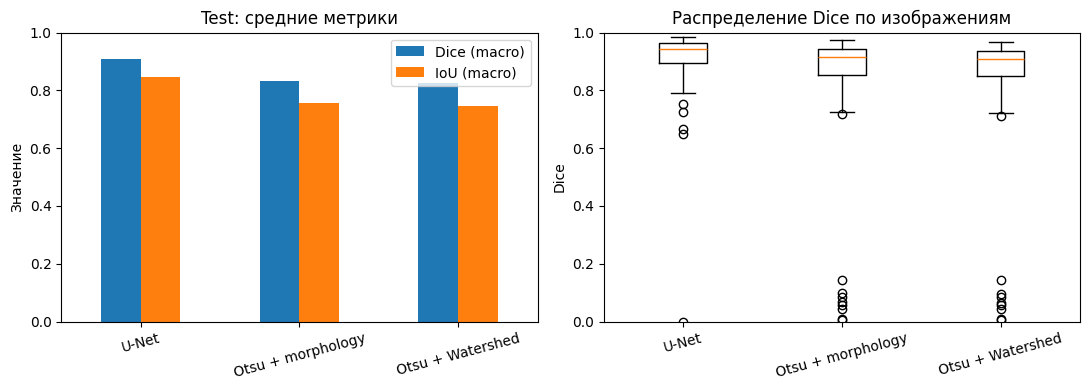

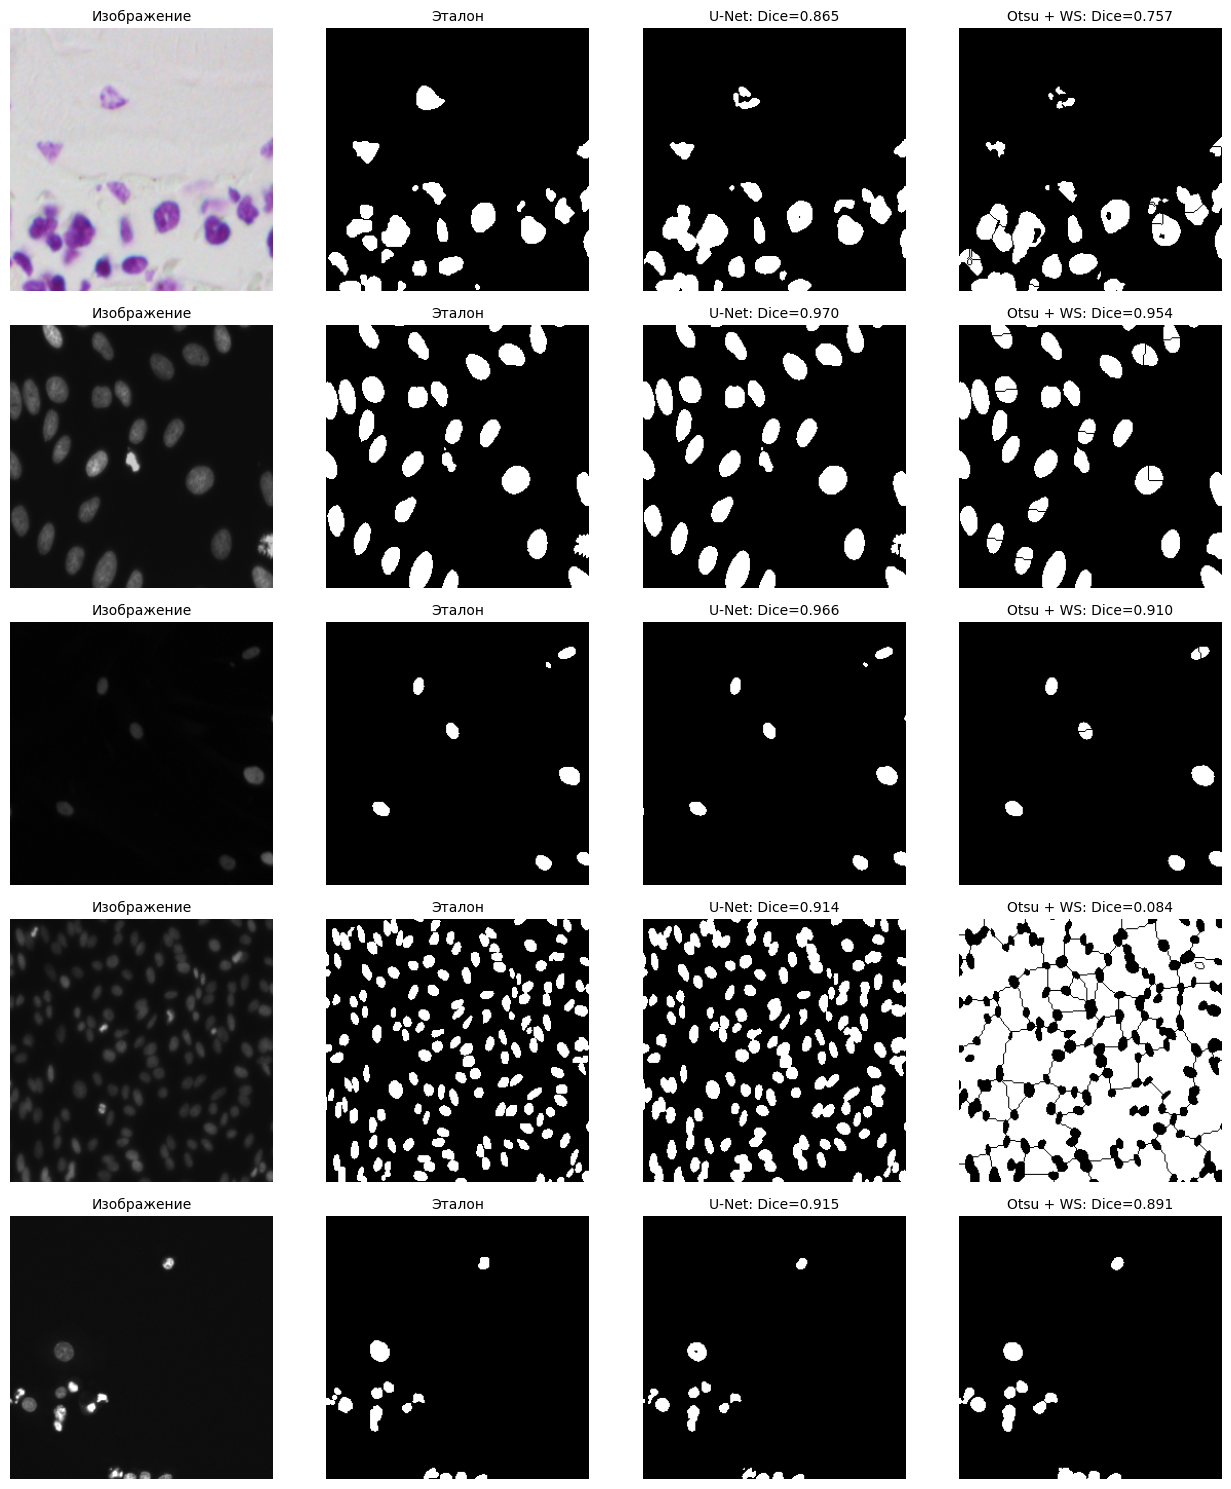

,id,dice,iou,precision,recall,tp,fp,fn,modality,foreground_fraction
0,e5aeb5b3577abbebe8982b5dd7d22c4257250ad3000661...,0.000000,0.000000,0.000000,0.000000,0,0,191,gray,0.002914
1,1a11552569160f0b1ea10bedbd628ce6c14f29edec5092...,0.648544,0.479885,0.595719,0.711648,501,340,203,gray,0.010722
2,8e8a7a14749d0b2e48de3d10e2e80063f17b165ad921c8...,0.665250,0.498408,0.516745,0.933532,2191,2049,156,gray,0.035812


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_frame = seg_summary.set_index('method')[['Dice (macro)', 'IoU (macro)']]
plot_frame.plot.bar(ax=axes[0], ylim=(0, 1), rot=15)
axes[0].set(title='Test: средние метрики', ylabel='Значение', xlabel='')
axes[1].boxplot([table.dice.to_numpy() for table in test_tables.values()],
                tick_labels=list(test_tables))
axes[1].tick_params(axis='x', rotation=15)
axes[1].set(title='Распределение Dice по изображениям', ylabel='Dice', ylim=(0, 1))
plt.tight_layout()
plt.savefig(RESULTS / 'segmentation_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# Фиксированная случайная выборка, а не только удачные примеры.
chosen = np.random.default_rng(SEED).choice(len(test_predictions), size=min(5, len(test_predictions)), replace=False)
classic_by_id = {sample['id']: sample for sample in classic_test_inputs}
fig, axes = plt.subplots(len(chosen), 4, figsize=(13, 3 * len(chosen)), squeeze=False)
for row_number, index in enumerate(chosen):
    sample = test_predictions[index]
    image = classic_by_id[sample['id']]['image']
    unet_mask = sample['probability'] >= seg_threshold
    classic_mask, _ = classical_segment(image, classic_selected['Otsu + Watershed'])
    pictures = [image, sample['target'], unet_mask, classic_mask]
    titles = ['Изображение', 'Эталон',
              f"U-Net: Dice={binary_metrics(sample['target'], unet_mask)['dice']:.3f}",
              f"Otsu + WS: Dice={binary_metrics(sample['target'], classic_mask)['dice']:.3f}"]
    for ax, picture, title in zip(axes[row_number], pictures, titles):
        ax.imshow(picture, cmap=None if picture.ndim == 3 else 'gray')
        ax.set_title(title, fontsize=10); ax.axis('off')
plt.tight_layout()
plt.savefig(RESULTS / 'segmentation_examples.png', dpi=150, bbox_inches='tight')
plt.show()

# Разбор трёх худших случаев U-Net помогает увидеть ограничения.
worst = test_tables['U-Net'].nsmallest(3, 'dice')
display(worst.merge(seg_frames['test'][['id', 'modality', 'foreground_fraction']], on='id'))


In [ ]:
unet_dice = float(seg_summary.loc[seg_summary.method == 'U-Net', 'Dice (macro)'].iloc[0])
classic_name = max(classic_selected, key=lambda name: float(
    classic_validation.loc[classic_validation.watershed == classic_selected[name]['watershed'],
                           'val_dice'].max()))
classic_dice = float(seg_summary.loc[seg_summary.method == classic_name, 'Dice (macro)'].iloc[0])
delta, interval = paired_bootstrap(test_tables['U-Net'], test_tables[classic_name])
if interval[0] > 0:
    interpretation = 'На этом test U-Net имеет преимущество; парный интервал разницы не включает ноль.'
elif interval[1] < 0:
    interpretation = ('На этом test классический метод лучше. Следует проверить обучение, '
                      'дисбаланс, размер изображений и число эпох U-Net.')
else:
    interpretation = ('Интервал разницы включает ноль: устойчивое преимущество по этим данным '
                      'не подтверждено.')
experiment_lines = '\n'.join(
    f"- `{row.name}`: validation Dice={row.val_dice:.4f}, порог={row.threshold:.2f}, "
    f"обучение={row.train_seconds/60:.1f} мин." for row in seg_results.itertuples())
conclusion = (
    '## Выводы по заданию 2\n\n' + experiment_lines + '\n\n'
    f"По validation выбрана `{seg_best_row['name']}`, эпоха {seg_checkpoint['epoch']}, "
    f"порог {seg_threshold:.2f}. На test средний Dice U-Net = **{unet_dice:.4f}**; "
    f"у выбранного по validation классического варианта `{classic_name}` = **{classic_dice:.4f}**. "
    f"Разница = {delta:+.4f}, парный bootstrap 95% CI [{interval[0]:+.4f}; {interval[1]:+.4f}]. "
    + interpretation + '\n\n'
    'Otsu опирается на интенсивность и чувствителен к окрашиванию и фону. U-Net может '
    'использовать пространственные признаки, но нуждается в обучении. Watershed разделяет '
    'ядра, однако не гарантирует улучшения бинарного Dice. Это проверяется отдельной строкой '
    'таблицы. Цена U-Net — время обучения и использование GPU.\n\n'
    'Ограничения: один seed обучения, небольшой test, неоднородные условия микроскопии, '
    'разбиение по изображениям без гарантии независимости экспериментов, размер 256×256. '
    'Следующие эксперименты: три seed, 384×384/тайлы, одинаковая длительность обучения, '
    'анализ ошибок отдельно для цветных и серых изображений. Выбирать новую конфигурацию '
    'после просмотра test и повторно называть его независимым нельзя.')
display(Markdown(conclusion))
(RESULTS / 'segmentation_conclusions.md').write_text(conclusion, encoding='utf-8')
print('Числа автоматически подставлены из выполненного эксперимента.')


## Выводы по заданию 2

- `bce_no_aug`: validation Dice=0.8925, порог=0.45, обучение=6.7 мин.
- `bce_dice_no_aug`: validation Dice=0.8964, порог=0.40, обучение=6.8 мин.
- `bce_dice_aug`: validation Dice=0.8926, порог=0.50, обучение=6.9 мин.

По validation выбрана `bce_dice_no_aug`, эпоха 16, порог 0.40. На test средний Dice U-Net = **0.9091**; у выбранного по validation классического варианта `Otsu + morphology` = **0.8308**. Разница = +0.0784, парный bootstrap 95% CI [+0.0394; +0.1225]. На этом test U-Net имеет преимущество; парный интервал разницы не включает ноль.

Otsu опирается на интенсивность и чувствителен к окрашиванию и фону. U-Net может использовать пространственные признаки, но нуждается в обучении. Watershed разделяет ядра, однако не гарантирует улучшения бинарного Dice. Это проверяется отдельной строкой таблицы. Цена U-Net — время обучения и использование GPU.

Ограничения: один seed обучения, небольшой test, неоднородные условия микроскопии, разбиение по изображениям без гарантии независимости экспериментов, размер 256×256. Следующие эксперименты: три seed, 384×384/тайлы, одинаковая длительность обучения, анализ ошибок отдельно для цветных и серых изображений. Выбирать новую конфигурацию после просмотра test и повторно называть его независимым нельзя.

Числа автоматически подставлены из выполненного эксперимента.
